In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('/content/CodeAlpha_WebScraping (1).csv')
df

,Title,Price,Availability
0,A Light in the Attic,Â£51.77,In stock
1,Tipping the Velvet,Â£53.74,In stock
2,Soumission,Â£50.10,In stock
3,Sharp Objects,Â£47.82,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,In stock
...,...,...,...
995,Alice in Wonderland (Alice's Adventures in Won...,Â£55.53,In stock
996,"Ajin: Demi-Human, Volume 1 (Ajin: Demi-Human #1)",Â£57.06,In stock
997,A Spy's Devotion (The Regency Spies of London #1),Â£16.97,In stock
998,1st to Die (Women's Murder Club #1),Â£53.98,In stock


In [3]:
df.head()

,Title,Price,Availability
0,A Light in the Attic,Â£51.77,In stock
1,Tipping the Velvet,Â£53.74,In stock
2,Soumission,Â£50.10,In stock
3,Sharp Objects,Â£47.82,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,In stock


In [4]:
print("dataset shape:",df.shape)


dataset shape: (1000, 3)


In [5]:
print("rows:",df.shape[0])
print("column:",df.shape[1])

rows: 1000
column: 3


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Title         1000 non-null   object
 1   Price         1000 non-null   object
 2   Availability  1000 non-null   object
dtypes: object(3)
memory usage: 23.6+ KB


In [7]:
df.describe(include='all')

,Title,Price,Availability
count,1000,1000,1000
unique,999,903,1
top,The Star-Touched Queen,Â£44.18,In stock
freq,2,3,1000


In [8]:
print("missing vales:")
print(df.isnull().sum())

missing vales:
Title           0
Price           0
Availability    0
dtype: int64


In [11]:
print("duplicate values:",df.duplicated().sum())

duplicate values: 0


In [13]:
print("unique value : ")
print(df.nunique())

unique value : 
Title           999
Price           903
Availability      1
dtype: int64


In [21]:
df['Price']=pd.to_numeric(df['Price'],errors='coerce')

#check price values
print(df['Price'].head())

0    51.77
1    53.74
2    50.10
3    47.82
4    54.23
Name: Price, dtype: float64


In [22]:
print("\naverage Price:",df['Price'].mean())
print("\nhighest Price:",df['Price'].max())
print("\nlowest Price:",df['Price'].min())
print("\nmedian Price",df['Price'].median())


average Price: 35.07035

highest Price: 59.99

lowest Price: 10.0

median Price 35.980000000000004


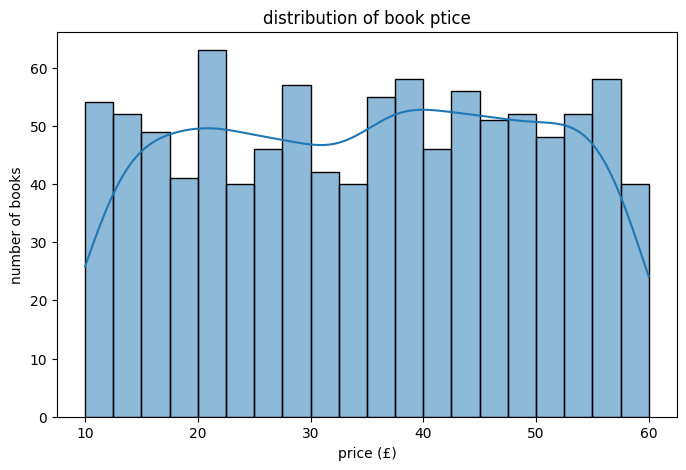

In [24]:
#book price distribution graph
plt.figure(figsize=(8,5))

#create histogram
sns.histplot(data=df,x='Price',bins=20,kde=True)

plt.title("distribution of book ptice")
plt.xlabel("price (£)")
plt.ylabel("number of books")

plt.show()

In [25]:
availabilty_counts=df['Availability'].value_counts()
print("availabilty counts :",availabilty_counts)

availabilty counts : Availability
In stock    1000
Name: count, dtype: int64


In [29]:
availabilty_percentage=df['Availability'].value_counts(normalize=True)*100
print("\navailabilty percentage :",availabilty_percentage.round(2))


availabilty percentage : Availability
In stock    100.0
Name: proportion, dtype: float64


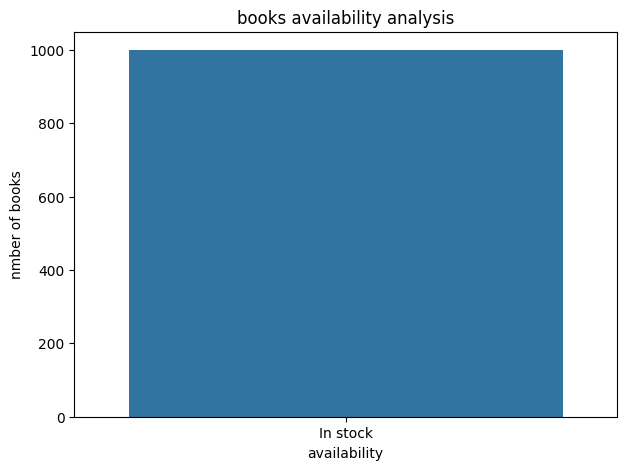

In [31]:
plt.figure(figsize=(7,5))

sns.countplot(data=df,x='Availability')

plt.title("books availability analysis")
plt.xlabel("availability")
plt.ylabel("nmber of books")

plt.show()

In [37]:
print("---------EDA FINAL INSIGHT----------")
print("1.total Books:",len(df))

print("2. average book price:",round(df['Price'].mean(),2))

print("3. highest book Price:",df['Price'].max())
print("4.lowest book price :",df['Price'].min())

print("5. total Availability books:",df['Availability'].str.contains('IN stock',case=False).sum())
print("6. missing values:",df.isnull().sum())

print("7.duplicate records :",df.duplicated().sum())

---------EDA FINAL INSIGHT----------
1.total Books: 1000
2. average book price: 35.07
3. highest book Price: 59.99
4.lowest book price : 10.0
5. total Availability books: 1000
6. missing values: Title           0
Price           0
Availability    0
dtype: int64
7.duplicate records : 0


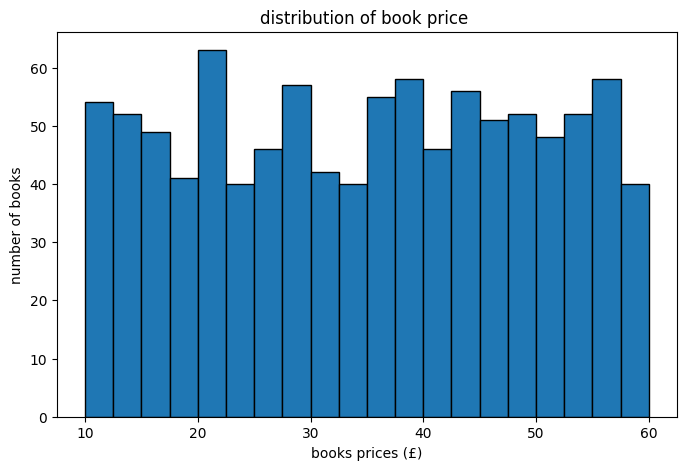

In [38]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.hist(df['Price'],bins=20,edgecolor='k')
plt.xlabel('books prices (£)')
plt.ylabel('number of books')
plt.title('distribution of book price ')
plt.show()

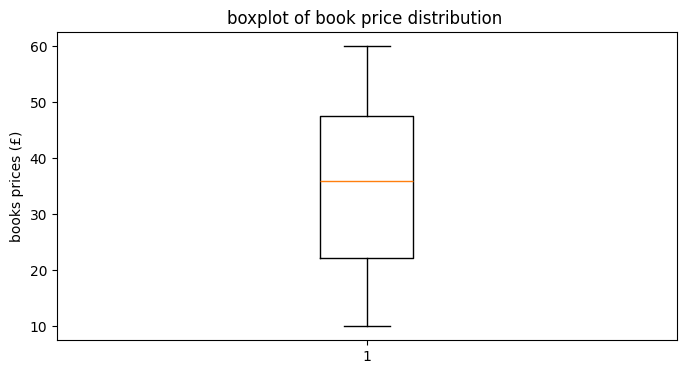

In [40]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.boxplot(df['Price'])
plt.ylabel('books prices (£)')
plt.title('boxplot of book price distribution ')
plt.show()

In [43]:
top_10_books=df.sort_values(by='Price',ascending=False).head(10)
print("top 10 expensive books:")
print(top_10_books[['Title','Price']])

top 10 expensive books:
                                                 Title  Price
648                 The Perfect Play (Play by Play #1)  59.99
617                  Last One Home (New Beginnings #1)  59.98
860                   Civilization and Its Discontents  59.95
560                     The Barefoot Contessa Cookbook  59.92
366                          The Diary of a Young Girl  59.90
657  The Bone Hunters (Lexy Vaughan & Steven Macaul...  59.71
133  Thomas Jefferson and the Tripoli Pirates: The ...  59.64
387                      Boar Island (Anna Pigeon #19)  59.48
549  The Man Who Mistook His Wife for a Hat and Oth...  59.45
393                          The Improbability of Love  59.45


In [44]:
#divide into price categories
df['Price_category']=pd.cut(df['Price'],bins=[0,10,20,30,40,50,100],labels=['0-10','10-20','20-30','30-40','40-50','50+']
)

print("books in each price range:",df['Price_category'].value_counts().sort_index())


books in each price range: Price_category
0-10       1
10-20    195
20-30    207
30-40    194
40-50    205
50+      198
Name: count, dtype: int64


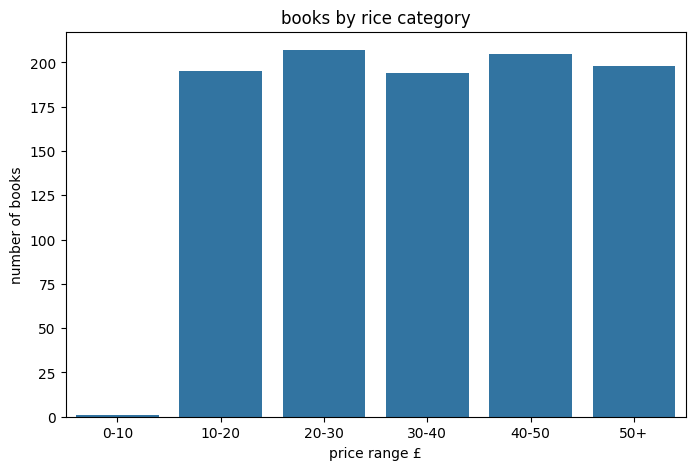

In [45]:
plt.figure(figsize=(8,5))
sns.countplot(data=df,x='Price_category')
plt.title("books by rice category")
plt.xlabel("price range £")
plt.ylabel("number of books")
plt.show()

In [47]:
#correaltion
correlation=df[['Price']].corr()
print("correlation Matrix:",correlation)

correlation Matrix:        Price
Price    1.0


In [49]:
print("========== FINAL EDA SUMMARY ==========")

print("Total Books:", len(df))
print("Average Price:", round(df['Price'].mean(), 2))
print("Maximum Price:", df['Price'].max())
print("Minimum Price:", df['Price'].min())

print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("Price Standard Deviation:",
      round(df['Price'].std(), 2))

print("Most Common Price Category:")
print(df['Price_category'].mode()[0])

========== FINAL EDA SUMMARY ==========
Total Books: 1000
Average Price: 35.07
Maximum Price: 59.99
Minimum Price: 10.0
Missing Values: 0
Duplicate Rows: 0
Price Standard Deviation: 14.45
Most Common Price Category:
20-30


Conclusion – Exploratory Data Analysis

In this project, Exploratory Data Analysis (EDA) was performed on a dataset containing 1,000 books collected from the Books to Scrape website.

The analysis included:

1. Examining the dataset structure and data types.
2. Checking missing values and duplicate records.
3. Calculating average, minimum and maximum book prices.
4. Analyzing book price distribution using histograms.
5. Identifying possible outliers using box plots.
6. Finding the top 10 most expensive books.
7. Grouping books into different price categories.
8. Analyzing book availability.

Key Findings

* The dataset contains 1,000 book records.
* All books are marked as in stock in the collected dataset.
* No missing values or duplicate records were found.
* The average book price is approximately £35.07.

Final Result

EDA helped us understand the dataset structure, price distribution, availability and overall data quality. Visualizations and statistical methods made the patterns easier to understand.
